In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_PATH = '/content/drive/MyDrive/SIMUTEH/simuteh-2330511078'

os.chdir(os.path.join(PROJECT_PATH, "notebook"))
sys.path.insert(0, os.path.join(PROJECT_PATH, "src"))

**Langkah 3.2 Diagnosis mutu**

Kode 3.1 Statistik dan histogram untuk diagnosis

Analisis Diagnosisi Mutu Citra


teh_041.png {'rerata': 171.8, 'simpangan_baku': 36.5, 'min': 75, 'maks': 217, 'persen_gelap': 0.0, 'persen_terang': 0.8}
teh_042.png {'rerata': 116.6, 'simpangan_baku': 38.6, 'min': 11, 'maks': 181, 'persen_gelap': 8.0, 'persen_terang': 0.0}
teh_043.png {'rerata': 211.2, 'simpangan_baku': 24.5, 'min': 133, 'maks': 251, 'persen_gelap': 0.0, 'persen_terang': 79.7}
teh_044.png {'rerata': 155.2, 'simpangan_baku': 14.4, 'min': 111, 'maks': 181, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 132.4, 'simpangan_baku': 57.3, 'min': 26, 'maks': 251, 'persen_gelap': 1.3, 'persen_terang': 16.7}


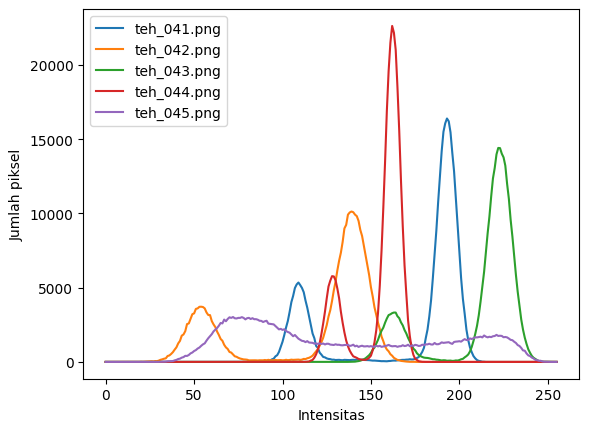

In [ ]:
from utils_cv import statistik, baca

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:

    gray = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

Diagonosis hasil kelas ringan

teh_021.png {'rerata': 173.4, 'simpangan_baku': 40.4, 'min': 75, 'maks': 218, 'persen_gelap': 0.0, 'persen_terang': 1.4}
teh_022.png {'rerata': 133.1, 'simpangan_baku': 49.3, 'min': 9, 'maks': 196, 'persen_gelap': 17.6, 'persen_terang': 0.0}
teh_023.png {'rerata': 206.0, 'simpangan_baku': 27.7, 'min': 116, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 74.0}
teh_024.png {'rerata': 153.0, 'simpangan_baku': 18.0, 'min': 92, 'maks': 205, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 120.2, 'simpangan_baku': 58.2, 'min': 14, 'maks': 240, 'persen_gelap': 7.3, 'persen_terang': 8.7}


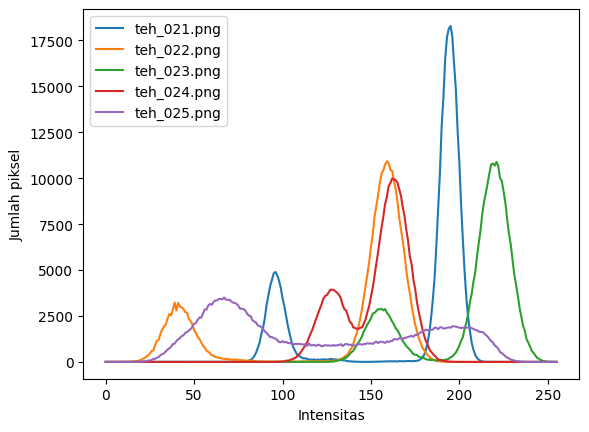

In [ ]:
for nama in ["teh_021.png", "teh_022.png", "teh_023.png",
             "teh_024.png", "teh_025.png"]:

    gray = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.savefig("../hasil/b3_histogram_kelas_ringan.png")
plt.show()

**Langkah 3.3 Perbaikan Citra**

Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi dan CLAHE

asli       KB=1.01 sigma=57.3
negatif    KB=1.01 sigma=57.3
cerah+50   KB=1.01 sigma=53.1
kontras    KB=1.01 sigma=76.4
regang     KB=1.04 sigma=80.3
gamma0.5   KB=0.92 sigma=40.0
gamma1.8   KB=1.17 sigma=64.7
ekualisasi KB=0.86 sigma=73.4
CLAHE      KB=1.72 sigma=48.4


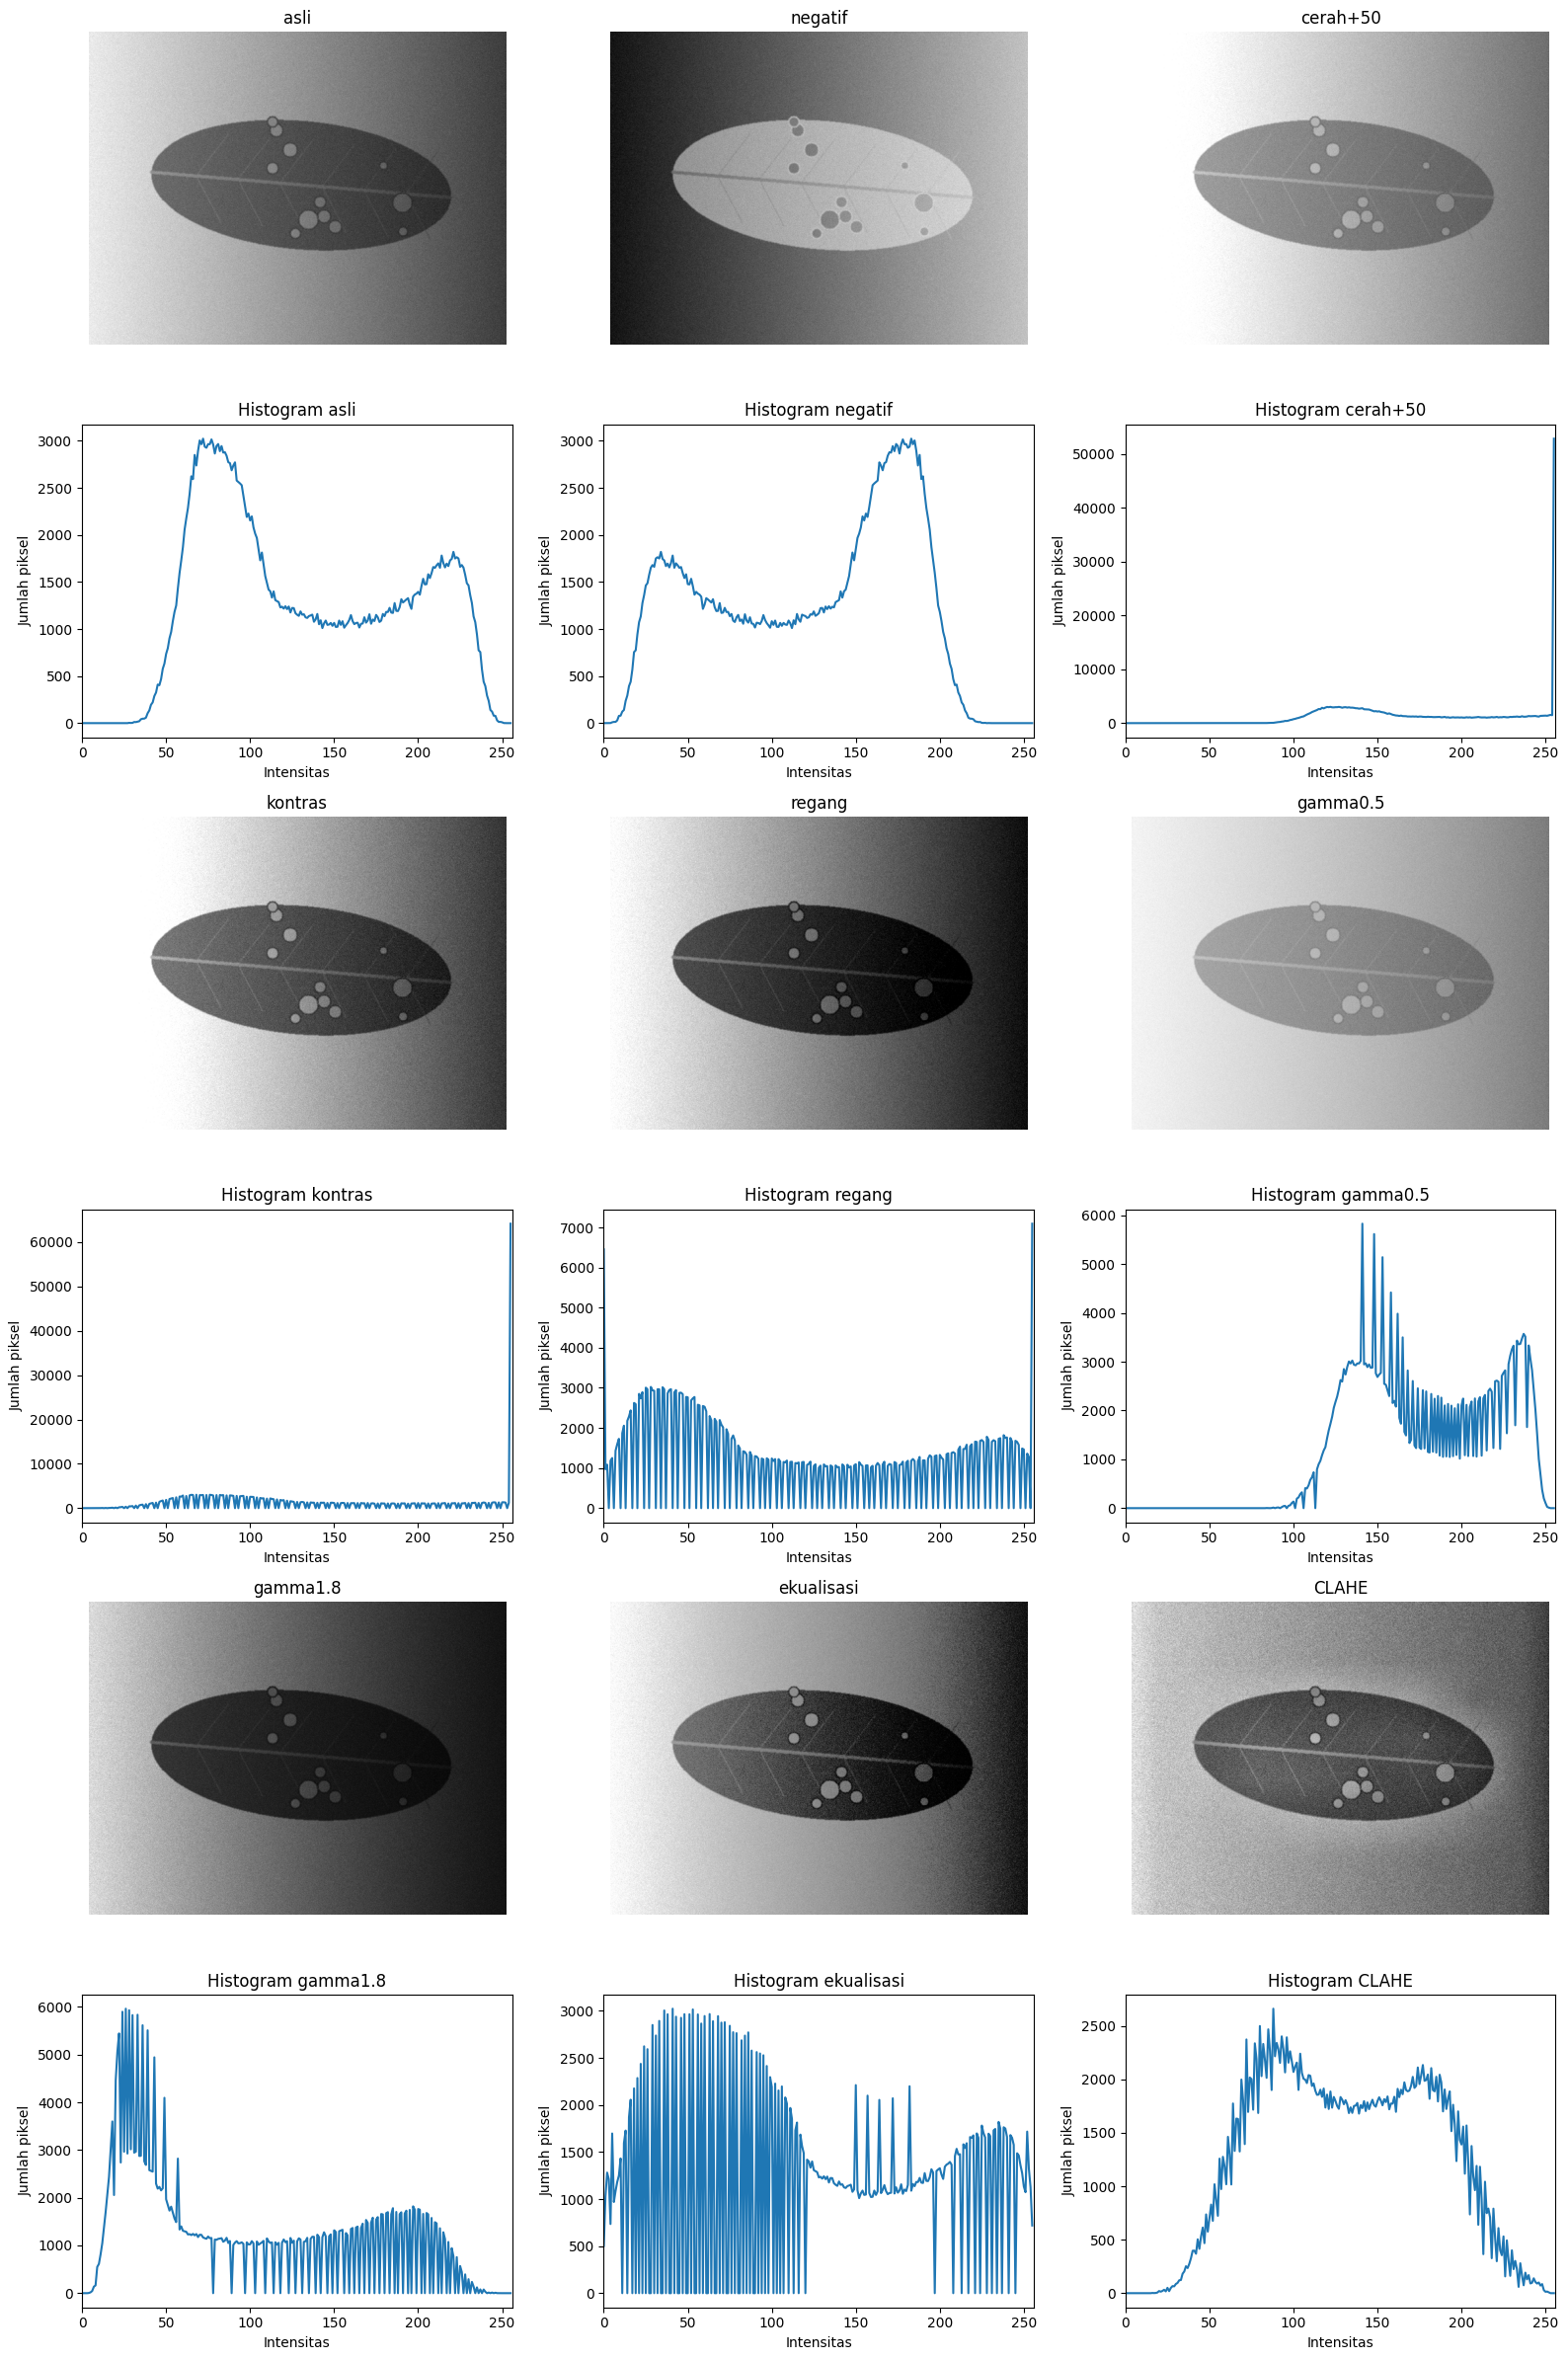

In [ ]:
from utils_cv import kontras_bercak

nama = "teh_045.png" # kondisi bayangan

img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(gray),
}

for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
          f"sigma={c.std():.1f}")

fig, axes = plt.subplots(6, 3, figsize=(16, 24))

nama_metode = list(hasil.keys())

for i, nm in enumerate(nama_metode):
    baris = (i // 3) * 2
    kolom = i % 3

    c = hasil[nm]

    # Citra hasil perbaikan
    axes[baris, kolom].imshow(c, cmap="gray", vmin=0, vmax=255)
    axes[baris, kolom].set_title(nm)
    axes[baris, kolom].axis("off")

    # Histogram tepat di bawah citra
    hist = cv2.calcHist([c], [0], None, [256], [0, 256])

    axes[baris + 1, kolom].plot(hist)
    axes[baris + 1, kolom].set_title(f"Histogram {nm}")
    axes[baris + 1, kolom].set_xlabel("Intensitas")
    axes[baris + 1, kolom].set_ylabel("Jumlah piksel")
    axes[baris + 1, kolom].set_xlim([0, 256])

plt.tight_layout()

plt.savefig(
    "../hasil/b3_perbaikan_histogram.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

**Langkah 3.4 Parameter CLAHE dan citra warna**

Kode 3.3 Eksperimen CLAHE

clip=1.0 tile=4: KB=1.92
clip=1.0 tile=8: KB=1.64
clip=1.0 tile=16: KB=1.60
clip=2.0 tile=4: KB=2.17
clip=2.0 tile=8: KB=1.72
clip=2.0 tile=16: KB=1.56
clip=4.0 tile=4: KB=2.08
clip=4.0 tile=8: KB=1.61
clip=4.0 tile=16: KB=1.52


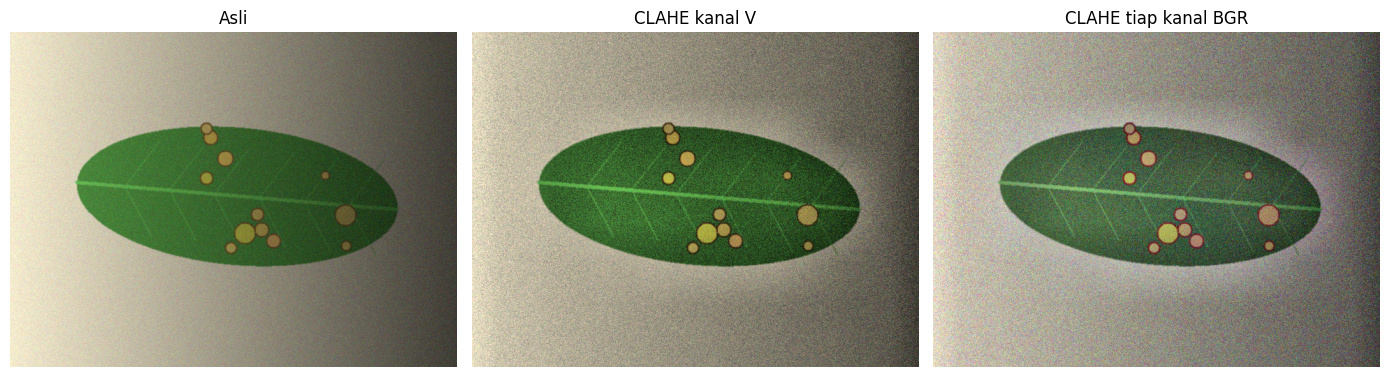

In [ ]:
from utils_cv import tampil
# Eksperimen parameter CLAHE

for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:

        c = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        ).apply(gray)

        print(
            f"clip={clip} tile={tile}: "
            f"KB={kontras_bercak(c, md, mb):.2f}"
        )


# CLAHE pada citra warna: kanal V dan tiap kanal BGR
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# CLAHE pada kanal V HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

# CLAHE pada setiap kanal BGR
via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

# Tampilkan perbandingan
tampil(
    [img, via_v, via_bgr],
    ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]
)

**Langkah 3.5 Kerjakan sendiri**

In [ ]:
# Daftar citra dan metode perbaikan
daftar_uji = [
    ("Gelap", "teh_042.png", "teh_022.png", "cerah"),
    ("Terang", "teh_043.png", "teh_023.png", "gelap"),
    ("Kontras rendah", "teh_044.png", "teh_024.png", "regang"),
    ("Bayangan", "teh_045.png", "teh_025.png", "clahe")
]

def perbaiki_citra(gray, metode):
    if metode == "cerah":
        return cv2.add(gray, 50)

    elif metode == "gelap":
        return cv2.subtract(gray, 50)

    elif metode == "regang":
        rmin, rmax = np.percentile(gray, (2, 98))
        return np.clip(
            (gray - rmin) / (rmax - rmin) * 255,
            0, 255
        ).astype(np.uint8)

    elif metode == "clahe":
        return cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(gray)


hasil_35 = []

for kondisi, file_berat, file_ringan, metode in daftar_uji:
    for kelas, nama in [
        ("Berat", file_berat),
        ("Ringan", file_ringan)
    ]:
        img = baca(f"../data/sintetis/citra/{nama}")
        md = cv2.imread(
            f"../data/sintetis/mask_daun/{nama}", 0
        )
        mb = cv2.imread(
            f"../data/sintetis/mask_bercak/{nama}", 0
        )

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hasil_perbaikan = perbaiki_citra(gray, metode)

        kb_awal = kontras_bercak(gray, md, mb)
        kb_akhir = kontras_bercak(hasil_perbaikan, md, mb)

        hasil_35.append({
            "kondisi": kondisi,
            "kelas": kelas,
            "citra": nama,
            "metode": metode,
            "KB_awal": round(kb_awal, 2),
            "KB_akhir": round(kb_akhir, 2)
        })

        print(
            f"{kondisi} | {kelas} | {nama} | "
            f"Metode: {metode} | "
            f"KB awal: {kb_awal:.2f} | "
            f"KB akhir: {kb_akhir:.2f}"
        )

tabel_35 = pd.DataFrame(hasil_35)
display(tabel_35)

tabel_35.to_csv(
    "../hasil/b3_perbaikan_4kondisi.csv",
    index=False
)

Gelap | Berat | teh_042.png | Metode: cerah | KB awal: 3.39 | KB akhir: 3.39
Gelap | Ringan | teh_022.png | Metode: cerah | KB awal: 3.76 | KB akhir: 3.76
Terang | Berat | teh_043.png | Metode: gelap | KB awal: 3.93 | KB akhir: 3.93
Terang | Ringan | teh_023.png | Metode: gelap | KB awal: 3.03 | KB akhir: 3.03
Kontras rendah | Berat | teh_044.png | Metode: regang | KB awal: 3.18 | KB akhir: 3.39
Kontras rendah | Ringan | teh_024.png | Metode: regang | KB awal: 1.61 | KB akhir: 1.69
Bayangan | Berat | teh_045.png | Metode: clahe | KB awal: 1.01 | KB akhir: 1.72
Bayangan | Ringan | teh_025.png | Metode: clahe | KB awal: 2.03 | KB akhir: 2.22


,kondisi,kelas,citra,metode,KB_awal,KB_akhir
0,Gelap,Berat,teh_042.png,cerah,3.39,3.39
1,Gelap,Ringan,teh_022.png,cerah,3.76,3.76
2,Terang,Berat,teh_043.png,gelap,3.93,3.93
3,Terang,Ringan,teh_023.png,gelap,3.03,3.03
4,Kontras rendah,Berat,teh_044.png,regang,3.18,3.39
5,Kontras rendah,Ringan,teh_024.png,regang,1.61,1.69
6,Bayangan,Berat,teh_045.png,clahe,1.01,1.72
7,Bayangan,Ringan,teh_025.png,clahe,2.03,2.22


In [ ]:
for kondisi, file_berat, file_ringan, metode in daftar_uji:

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    for baris, (kelas, nama) in enumerate([
        ("Berat", file_berat),
        ("Ringan", file_ringan)
    ]):
        img = baca(f"../data/sintetis/citra/{nama}")
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hasil_perbaikan = perbaiki_citra(gray, metode)

        axes[baris, 0].imshow(gray, cmap="gray")
        axes[baris, 0].set_title(f"{kelas} - Sebelum ({nama})")
        axes[baris, 0].axis("off")

        axes[baris, 1].imshow(hasil_perbaikan, cmap="gray")
        axes[baris, 1].set_title(f"{kelas} - Sesudah ({metode})")
        axes[baris, 1].axis("off")

    plt.suptitle(f"Perbaikan Citra Kondisi {kondisi}")
    plt.tight_layout()

    nama_simpan = kondisi.lower().replace(" ", "_")
    plt.savefig(
        f"../hasil/b3_perbaikan_{nama_simpan}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

Output hidden; open in https://colab.research.google.com to view.